# Experiment 07 — Function Distillation, Repeated on a Harder Teacher (CIFAR-10)

The interactive companion to `experiments/07_function_distillation_cifar10/`.
Full write-up: `experiments/07_function_distillation_cifar10/README.md`.

Experiment 05's exact study repeated against a harder, different teacher:
experiment 06's CIFAR-10 "is this an airplane?" CNN instead of experiment
04's MNIST digit-8 CNN. Same five student architectures (no convolution, no
pooling), same `MSE(student_logit, teacher_logit)` training objective, same
H×N parameter-matched grid. The question this notebook asks: do
experiment 05's findings (residual composition beats parameter-matched
plain depth; parallel width underperforms both) hold up on a genuinely
harder function, or were they an MNIST-specific artifact?

Loads results already produced by the pipeline scripts rather than
re-running the ~70-minute sweep interactively.

In [1]:
import csv
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.image as mpimg

REPO_ROOT = Path.cwd().parent
EXP_DIR = REPO_ROOT / "experiments" / "07_function_distillation_cifar10"
OUTPUTS = EXP_DIR / "outputs"
sys.path.insert(0, str(EXP_DIR))

from make_plots import ARCH_STYLE, load_results  # noqa: E402

%matplotlib inline

results = load_results()
print(f"{len(results)} student configs loaded from {OUTPUTS / 'results.csv'}")

34 student configs loaded from E:\projects\PytorchExperiments\experiments\07_function_distillation_cifar10\outputs\results.csv


## Headline comparison

Teacher logits here range roughly ±22 (narrower than MNIST's ±32) but the
function is harder to fit -- the best CIFAR-10 test MSE (6.55) is a much
larger fraction of its target's range than MNIST's best (1.03 of ±32).

In [2]:
highlight_names = [
    "linear", "conventional_mlp_H128", "deepplain_H128_N8",
    "compositional_H128_N8", "parallel_B32_W16",
]
by_name = {r["name"]: r for r in results}

header = f'{"model":24s} {"params":>9s} {"ReLU layers":>12s} {"train MSE":>10s} {"val MSE":>9s} {"test MSE":>9s} {"agreement":>10s}'
print(header)
print("-" * len(header))
for name in highlight_names:
    r = by_name[name]
    print(f'{name:24s} {int(r["n_params"]):9d} {int(r["n_relu_layers"]):12d} '
          f'{r["train_mse"]:10.3f} {r["val_mse"]:9.3f} {r["test_mse"]:9.3f} '
          f'{r["test_teacher_student_agreement"]:10.4f}')

model                       params  ReLU layers  train MSE   val MSE  test MSE  agreement
-----------------------------------------------------------------------------------------
linear                        3073            0     13.368    13.053    13.184     0.9347
conventional_mlp_H128       409985            2      7.590     8.059     7.776     0.9453
deepplain_H128_N8           789761           24      7.378     7.893     7.592     0.9470
compositional_H128_N8       789761           24      5.954     6.921     6.550     0.9536
parallel_B32_W16           1573889           32      8.455     9.048     8.696     0.9455


## Test function error vs. capacity

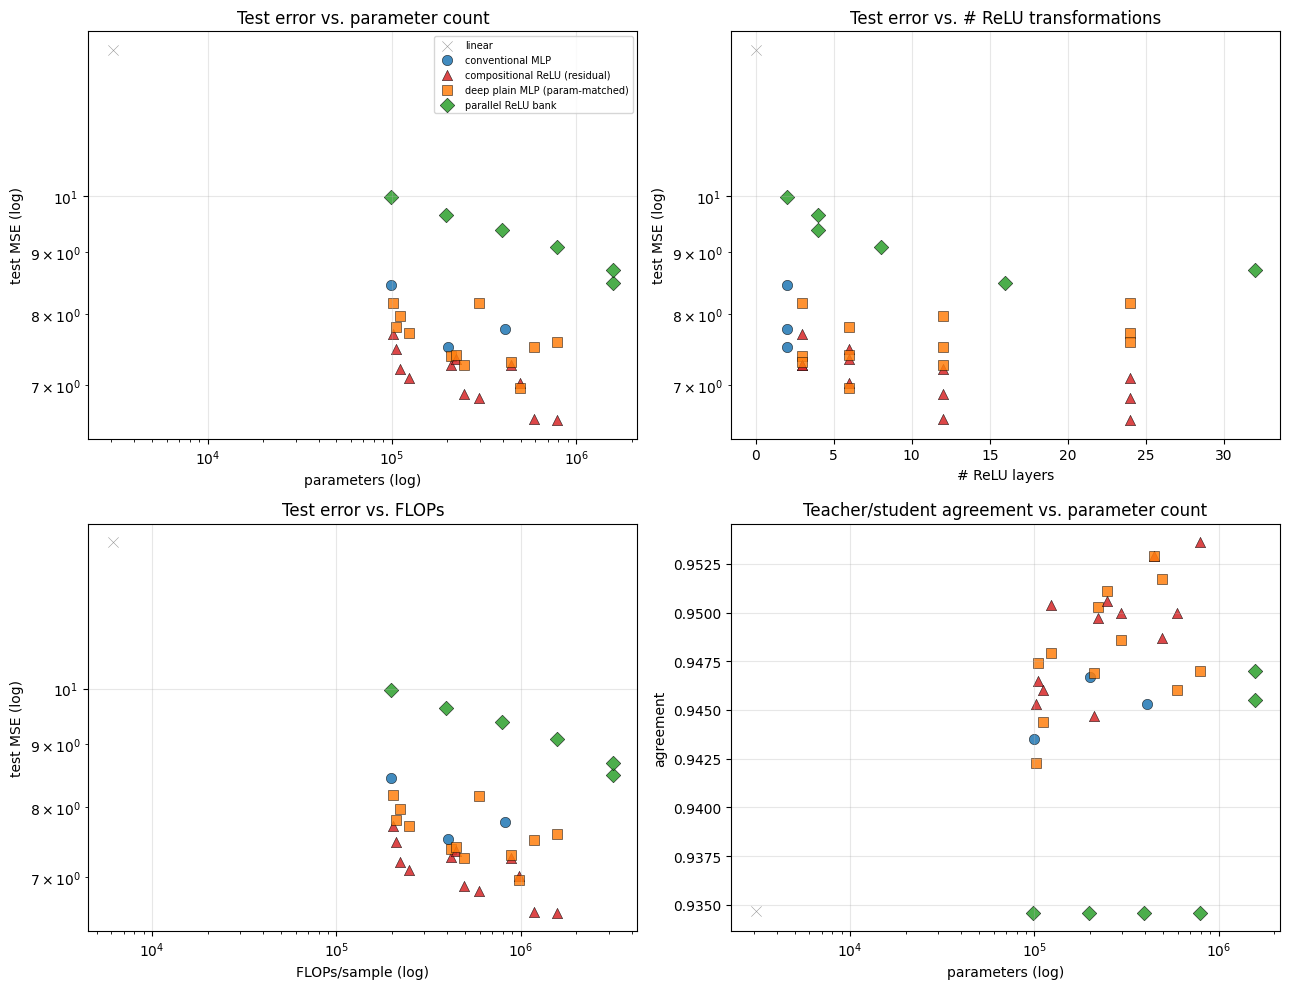

In [3]:
def scatter_by_arch(ax, x_key, y_key, logx=False, logy=False):
    seen = set()
    for r in results:
        style = ARCH_STYLE[r["arch"]]
        label = style["label"] if r["arch"] not in seen else None
        seen.add(r["arch"])
        ax.scatter(r[x_key], r[y_key], color=style["color"], marker=style["marker"],
                   s=55, alpha=0.85, label=label, edgecolors="black" if style["marker"] != "x" else None, linewidths=0.4)
    if logx: ax.set_xscale("log")
    if logy: ax.set_yscale("log")
    ax.grid(True, alpha=0.3)


fig, axes = plt.subplots(2, 2, figsize=(13, 10))

scatter_by_arch(axes[0, 0], "n_params", "test_mse", logx=True, logy=True)
axes[0, 0].set_xlabel("parameters (log)"); axes[0, 0].set_ylabel("test MSE (log)")
axes[0, 0].set_title("Test error vs. parameter count")
axes[0, 0].legend(fontsize=7)

scatter_by_arch(axes[0, 1], "n_relu_layers", "test_mse", logy=True)
axes[0, 1].set_xlabel("# ReLU layers"); axes[0, 1].set_ylabel("test MSE (log)")
axes[0, 1].set_title("Test error vs. # ReLU transformations")

scatter_by_arch(axes[1, 0], "flops_per_sample", "test_mse", logx=True, logy=True)
axes[1, 0].set_xlabel("FLOPs/sample (log)"); axes[1, 0].set_ylabel("test MSE (log)")
axes[1, 0].set_title("Test error vs. FLOPs")

scatter_by_arch(axes[1, 1], "n_params", "test_teacher_student_agreement", logx=True)
axes[1, 1].set_xlabel("parameters (log)"); axes[1, 1].set_ylabel("agreement")
axes[1, 1].set_title("Teacher/student agreement vs. parameter count")

fig.tight_layout()
plt.show()

## The core ablation, replicated: residual structure vs. depth at IDENTICAL params

Same design as experiment 05: `compositional_relu(H, N)` and
`deep_plain_mlp(H, n_layers=3N)` have exactly matched parameter counts. On
this harder teacher, the "plain gets worse with depth" pathology is if
anything *more* pronounced -- at H=64 and H=128, the plain model's test MSE
at N=8 is worse than at N=1.

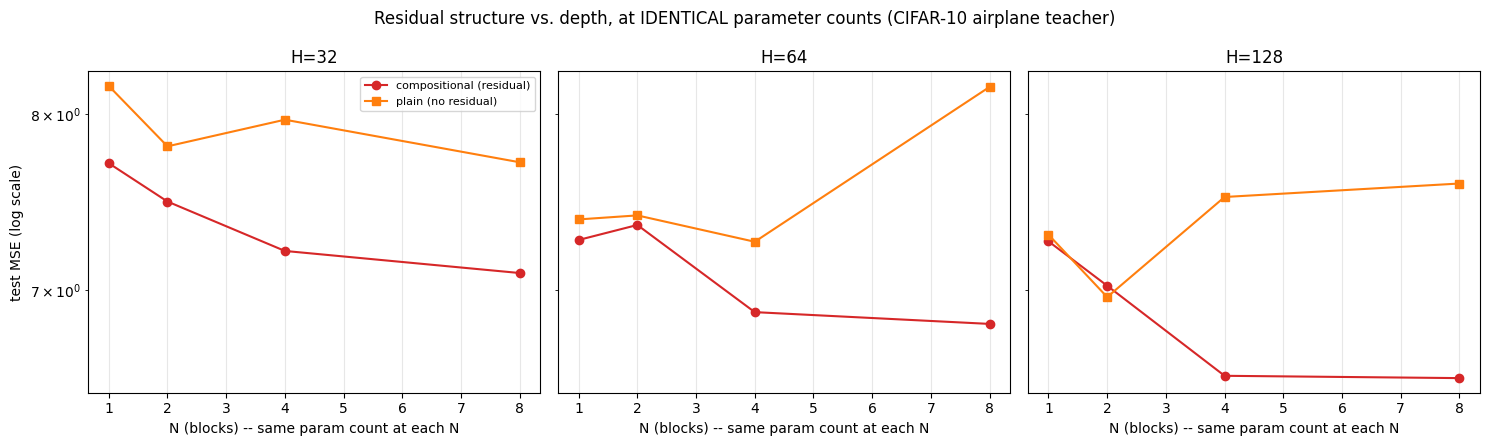

H=64 and H=128: plain deep_plain_mlp is WORSE at N=8 than at N=1 -- replicating and
sharpening the MNIST finding on a harder, unrelated teacher:
  H=64: plain N=1 -> 7.388   plain N=8 -> 8.169
  H=128: plain N=1 -> 7.303   plain N=8 -> 7.592


In [4]:
from collections import defaultdict

by_h = defaultdict(lambda: defaultdict(dict))
for r in results:
    if r["arch"] in ("compositional_relu", "deep_plain_mlp"):
        h = int(r["cfg_hidden"])
        n = int(r["cfg_n_blocks"]) if r["arch"] == "compositional_relu" else int(r["cfg_n_layers"]) // 3
        by_h[h][n][r["arch"]] = r["test_mse"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, h in zip(axes, sorted(by_h)):
    ns = sorted(by_h[h])
    comp = [by_h[h][n].get("compositional_relu") for n in ns]
    plain = [by_h[h][n].get("deep_plain_mlp") for n in ns]
    ax.plot(ns, comp, "o-", color=ARCH_STYLE["compositional_relu"]["color"], label="compositional (residual)")
    ax.plot(ns, plain, "s-", color=ARCH_STYLE["deep_plain_mlp"]["color"], label="plain (no residual)")
    ax.set_title(f"H={h}")
    ax.set_xlabel("N (blocks) -- same param count at each N")
    ax.set_yscale("log")
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("test MSE (log scale)")
axes[0].legend(fontsize=8)
fig.suptitle("Residual structure vs. depth, at IDENTICAL parameter counts (CIFAR-10 airplane teacher)")
fig.tight_layout()
plt.show()

print("H=64 and H=128: plain deep_plain_mlp is WORSE at N=8 than at N=1 -- replicating and")
print("sharpening the MNIST finding on a harder, unrelated teacher:")
for h in (64, 128):
    print(f"  H={h}: plain N=1 -> {by_h[h][1]['deep_plain_mlp']:.3f}   plain N=8 -> {by_h[h][8]['deep_plain_mlp']:.3f}")

## Robustness: the Gaussian-noise exception, again

Test images perturbed with translation, rotation, Gaussian noise, and
brightness shifts (never seen during distillation). Compositional keeps its
lead on 3 of 4 perturbation types -- but not Gaussian noise, exactly the
same specific exception found in experiment 05's MNIST study. Two-for-two
now, on unrelated teachers -- this looks like a real, repeatable limitation
of the residual architecture's noise sensitivity.

In [5]:
with open(OUTPUTS / "robustness_results.csv") as f:
    rob_rows = list(csv.DictReader(f))

conditions = ["clean_test", "translate_2px", "rotate_10deg", "gaussian_noise", "brightness_1.3x"]
models_order = ["linear", "conventional_mlp_H128", "deepplain_H128_N8", "compositional_H128_N8", "parallel_B32_W16"]

header = f'{"model":24s}' + "".join(f'{c:>18s}' for c in conditions)
print(header)
for m in models_order:
    row = {r["condition"]: float(r["mse"]) for r in rob_rows if r["model"] == m}
    print(f'{m:24s}' + "".join(f'{row.get(c, float("nan")):18.2f}' for c in conditions))

model                           clean_test     translate_2px      rotate_10deg    gaussian_noise   brightness_1.3x
linear                               13.88             28.52             23.48             15.64             19.21
conventional_mlp_H128                 8.28             13.23             10.30              9.64             11.06
deepplain_H128_N8                     8.04             11.48             11.32             11.41             10.63
compositional_H128_N8                 6.83             10.66              9.16             11.33              9.23
parallel_B32_W16                      8.79             12.26             13.44             15.11             10.46


## Worst-case disagreements

Unlike MNIST (2/16 worst cases were genuine classification flips), **5/16**
here are real disagreements (red titles) -- several are actual airplane
photos the CNN correctly identified that the student confidently got
wrong. Harder, more visually diverse input domains appear to cost the
student real task accuracy, not just logit-magnitude precision.

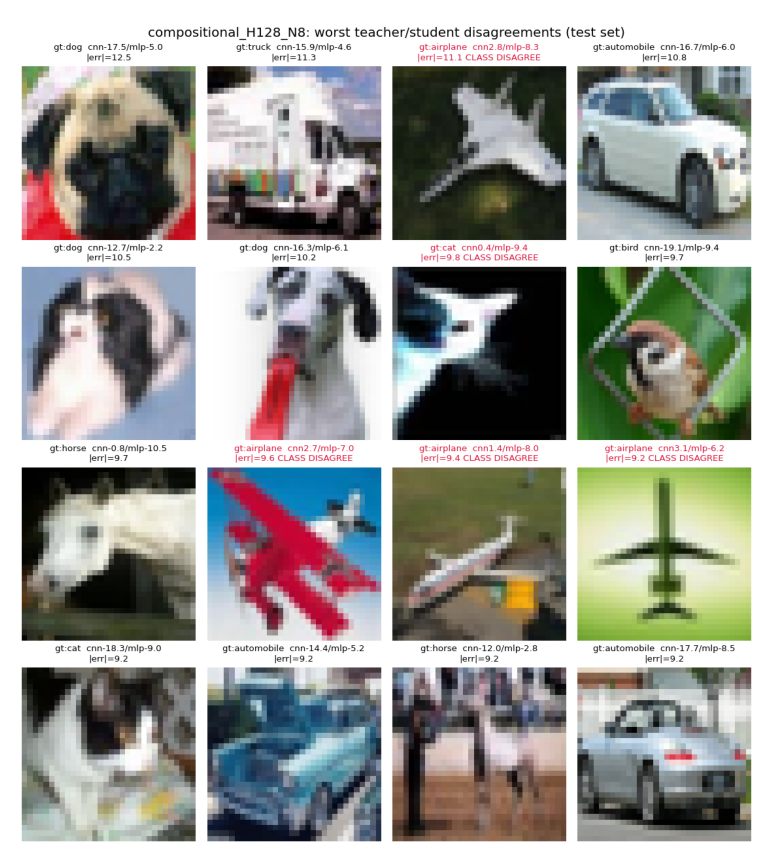

In [6]:
img = mpimg.imread(OUTPUTS / "worst_cases" / "compositional_H128_N8_worst_cases.png")
plt.figure(figsize=(11, 11))
plt.imshow(img)
plt.axis("off")
plt.show()

## Takeaways: does this replicate experiment 05?

- **Yes, on the core structural claims.** Residual composition beats
  parameter-matched plain depth (and the plain-gets-worse-with-depth
  pathology is sharper here); parallel width underperforms both at every
  budget tested, by an even wider margin than on MNIST.
- **Yes, on the one exception too.** Compositional loses to simpler models
  specifically under Gaussian noise -- on both teachers. That consistency
  is more convincing than either result alone.
- **What's different:** this harder teacher shows earlier diminishing
  returns (H=128's N=4 and N=8 are statistically tied, unlike MNIST where
  the largest model was clearly best) and a much sharper ground-truth
  recall collapse for small students (see the README's
  `evaluate_ground_truth.py` result: the smallest MLP keeps only 11% of the
  teacher's already-modest recall, vs. 84% on MNIST). The worst-case
  analysis also surfaced far more genuine classification errors (5/16 vs.
  2/16) -- a harder, more visually diverse function costs the student real
  task accuracy, not just precision on the logit itself.
- **Verdict:** the same qualified conclusion as experiment 05 -- weak-form
  support (a non-convolutional architecture *can* represent the function),
  no support for the strong form (transformation count alone, independent
  of structure) -- now cross-validated against a second, unrelated,
  harder teacher rather than resting on one dataset.

Full write-up, all 34 raw results, and reproduction commands:
`experiments/07_function_distillation_cifar10/README.md`.